# Do the Fig 2 *in vivo* atlas states exist in the human tissue data?

Benchmark against **Figure 2** of Nikolakopoulou et al. 2026 (the *in vivo* endometrial atlas,
14 epithelial states) — the identity/phase scheme, which is the right reference for tissue
(the Fig 4 panel is organoid wound-response states and doesn't apply here).

No re-clustering: we use the existing `leiden_scVI_3.0` from the **04b latent**, the clustering
your committed labels were rolled up from, so hits map straight back. Two readouts: a grouped
dotplot (visual smear test) and a **per-state module score** matrix (which leiden cluster looks
like which Fig 2 state). Run in order; check the load/introspect cell before plotting.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import scanpy as sc, anndata as ad, pandas as pd, numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
sc.settings.verbosity = 1

LATENT = "data/interim/latent_human_epithelial.h5ad"   # 04b -- leiden_scVI_3.0 valid HERE
CSV    = "resources/annotations/human_epithelial.csv"  # committed  cluster,label
USE_RAW = False   # score + dotplot on .X. If .X is scaled and .raw holds lognorm counts, set True.

In [2]:
# Fig 2 in vivo atlas -- 14 epithelial states. Curated from the paper's TEXT (the defining
# markers named per cluster), not a pixel-transcription of the Fig 2C panel. Genes not in your
# object are dropped + reported below.
MARKERS = {
    "ciliated":                        ["FOXJ1","PIFO","RSPH1","TPPP3"],
    "pre-ciliated":                    ["FOXJ1","MCIDAS","CCNO","CDC20B","MAD2L1","NEK2"],
    "cycling":                         ["MKI67","PCNA","BIRC5"],
    "hormone-responsive PGRhigh":      ["PGR","ESR1"],
    "hormone-responsive PGRlow":       ["PGR","ESR1"],    # LOW PGR -- see notes; no positive marker
    "secretory early":                 ["SCGB2A1","SCGB2A2","SCGB1D2","SCGB1D4"],
    "secretory mid":                   ["PAEP","SCGB2A1","SCGB2A2"],   # intermediate on secretory axis
    "secretory late":                  ["PAEP","SPP1","S100P"],
    "receptivity-associated luminal":  ["IL6","ENPP3","LGR5","SCGB1D2","PTGS2"],  # paper writes "PTGS"
    "regeneration-associated luminal": ["PLAU","MMP7","CSF1","ITGA2","CD47","WNT7A"],
    "KRT5+":                           ["KRT5"],
    "MUC5B+":                          ["MUC5B"],
    "transcriptionally active":        ["PNN","CCNL1","FUS","TEAD1","WWC1"],
    "VIM+":                            ["VIM","EPCAM"],
}
ALIASES = {}   # these symbols are standard; resolve() falls back to exact match
sum(len(v) for v in MARKERS.values())

47

## Load the 04b latent and see what's inside

Confirm a `leiden_scVI_*` column exists and that gene expression is present (if `X` has only a
few dims it's embeddings-only -- pull expression from `lineages/human_epithelial.h5ad` instead).

In [3]:
a = ad.read_h5ad(LATENT)
print(a)
leidens = [c for c in a.obs.columns if c.lower().startswith("leiden_scvi")]
print("leiden cols:", leidens)
print("X:", None if a.X is None else a.X.shape,
      "| raw:", a.raw is not None, "| layers:", list(a.layers.keys()))

AnnData object with n_obs × n_vars = 12179 × 36601
    obs: 'sample', 'species', 'timepoint', 'x_um_dbscan', 'y_um_dbscan', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo', 'doubletdetection_predicted_doublet', 'doubletdetection_doublet_score', 'cell_barcode', 'leiden_scVI_0.1', 'leiden_scVI_0.2', 'leiden_scVI_0.3', 'leiden_scVI_0.4', 'leiden_scVI_0.5', 'leiden_scVI_0.6', 'leiden_scVI_0.7', 'leiden_scVI_0.8', 'leiden_scVI_0.9', 'leiden_scVI_1.0', 'leiden_scVI_1.5', 'leiden_scVI_2.0', 'leiden_scVI_2.5', 'leiden_scVI_3.0', 'score_epithelial cells', 'score_endometrial fibroblasts', 'score_decidual cells', 'score_smooth muscle cells', 'score_immune cells', 'score_perivascular cells', 'celltype_ref', 'leiden_scVI_4.0', 'leiden_scVI_5.0', 'leiden_scVI_6.0', 'leiden_scVI_7.0', 'leiden_scVI_8.0', 'leiden_scVI_9.0', 'leiden_scVI_10.0', 'lineage', 'excluded'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'mito', 'highly_variable', 'highly_variable_ran

In [4]:
GROUP = "leiden_scVI_3.0" if "leiden_scVI_3.0" in a.obs else (leidens[-1] if leidens else None)
assert GROUP, "no leiden_scVI_* column found -- check the object"
a.obs[GROUP] = a.obs[GROUP].astype(str)
print(f"using leiden = {GROUP}  ({a.obs[GROUP].nunique()} clusters)")

def resolve(g):
    if g in a.var_names: return g
    for alt in ALIASES.get(g, []):
        if alt in a.var_names: return alt
    return None

MARKERS_present, missing = {}, []
for state, genes in MARKERS.items():
    present = [r for g in genes if (r := resolve(g))]
    missing += [g for g in genes if resolve(g) is None]
    if present:
        MARKERS_present[state] = present
missing = sorted(set(missing))
n_have  = sum(len(v) for v in MARKERS_present.values())
n_total = sum(len(v) for v in MARKERS.values())
print(f"{n_have}/{n_total} marker genes found across {len(MARKERS_present)} states.")
print(f"missing (dropped): {missing}")
if n_have < 0.5 * n_total:
    print("\n*** <50% found -- this latent likely stores embeddings only. Pull expression from "
          "lineages/human_epithelial.h5ad and transfer leiden by barcode instead. ***")

using leiden = leiden_scVI_3.0  (51 clusters)
47/47 marker genes found across 14 states.
missing (dropped): []


## Map committed labels onto these cells, and cross-tab

Labels come from the committed CSV (`leiden -> label`). Excluded 04c clusters aren't in the CSV,
so they land in `<excluded/unmapped>`.

In [5]:
csv = pd.read_csv(CSV, dtype=str)
lab = dict(zip(csv["cluster"], csv["label"]))
a.obs["committed_label"] = a.obs[GROUP].map(lab).fillna("<excluded/unmapped>")
print(f"CSV clusters: {len(lab)}  |  leiden clusters: {a.obs[GROUP].nunique()}")
ct = pd.crosstab(a.obs[GROUP], a.obs["committed_label"])
ct

CSV clusters: 51  |  leiden clusters: 51


committed_label,EXCLUDE,ciliated epithelium,epithelial cells
leiden_scVI_3.0,,,
0,0,0,209
1,463,0,0
10,0,0,289
11,238,0,0
12,0,0,405
13,0,0,327
14,0,0,288
15,0,0,267
16,0,0,129


## Dotplot: Fig 2 signatures over the existing leiden clusters

Grouped brackets = Fig 2 states. A state "exists" if its block lights up one/few distinct leiden
clusters.

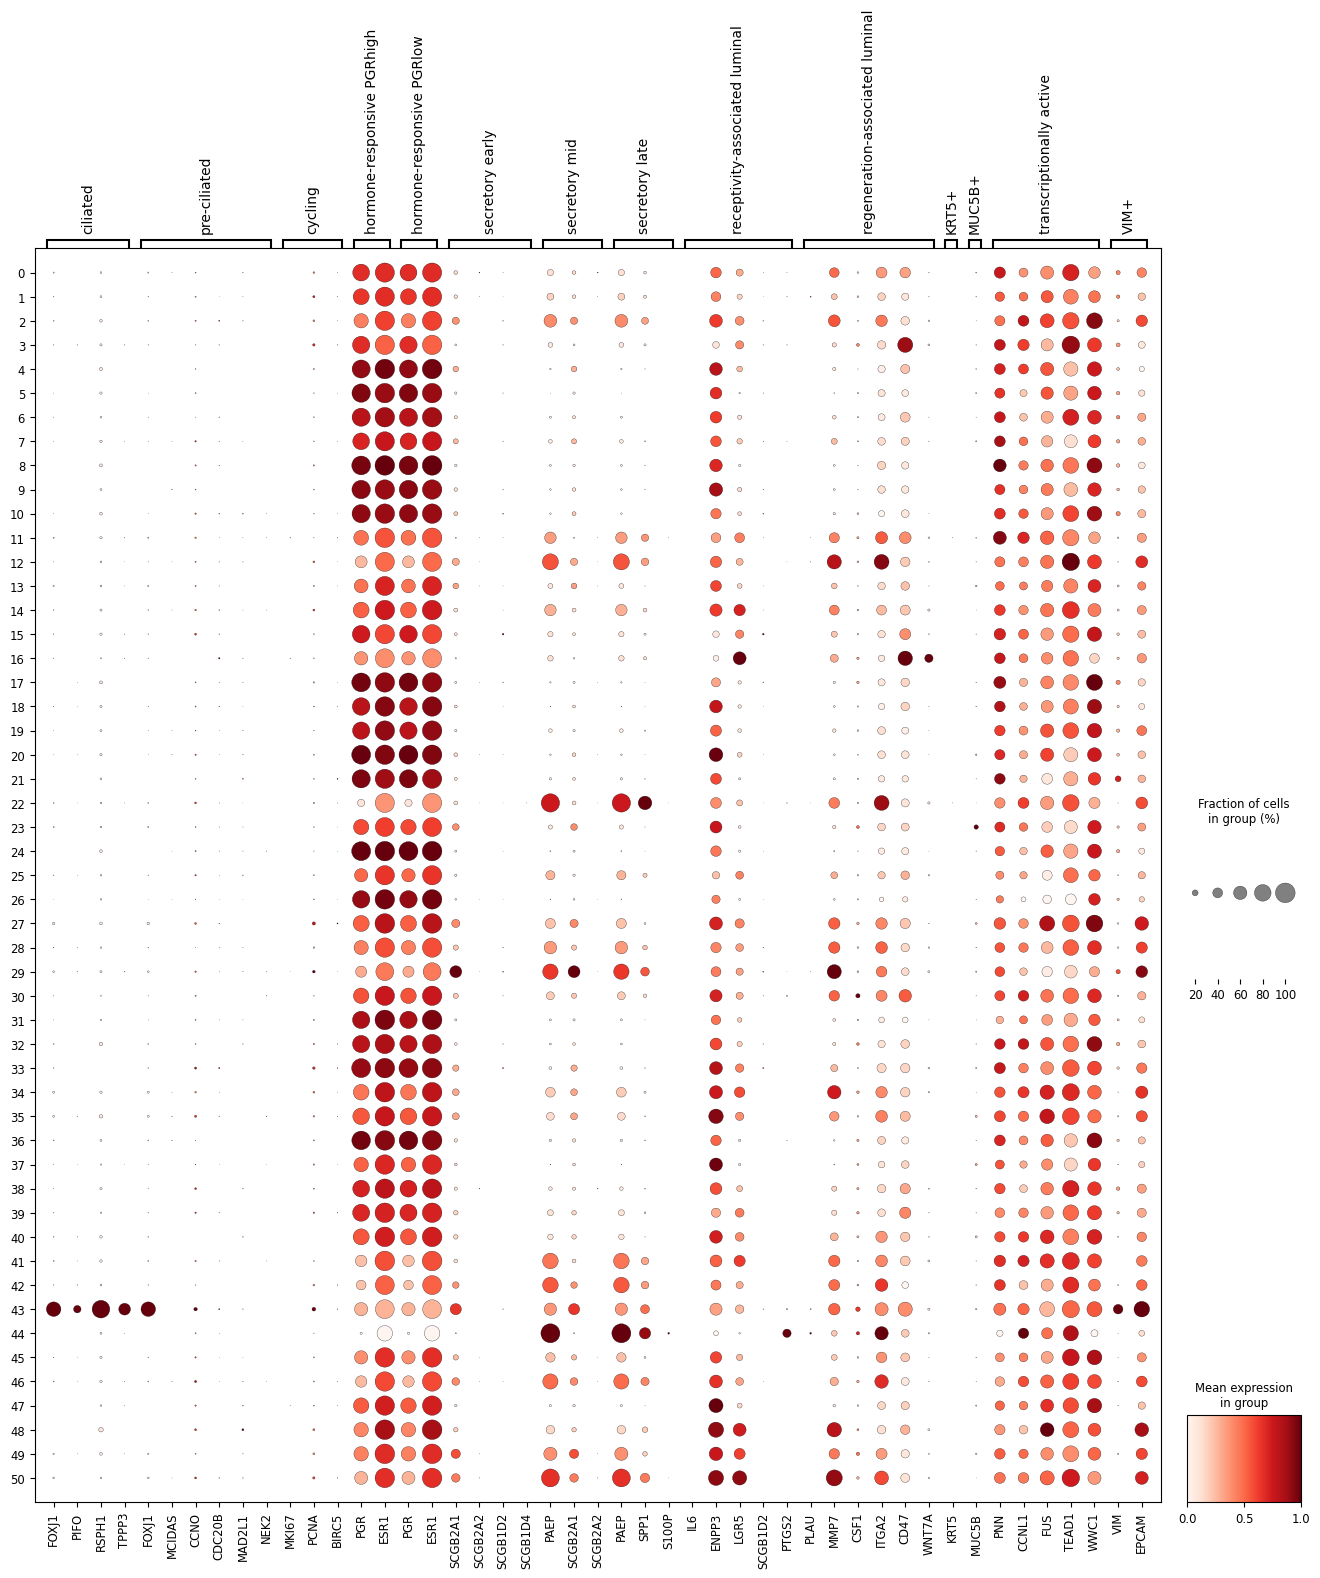

In [10]:
ng = sum(len(v) for v in MARKERS_present.values())
sc.pl.dotplot(a, MARKERS_present, groupby=GROUP, standard_scale="var", use_raw=USE_RAW,
              figsize=(ng * 0.22 + 6, a.obs[GROUP].nunique() * 0.28 + 2), save = 'epidot')

## Same, over the committed labels

If a state's block is crisp in the leiden view but smears together here, it's hiding inside a
broad committed label.

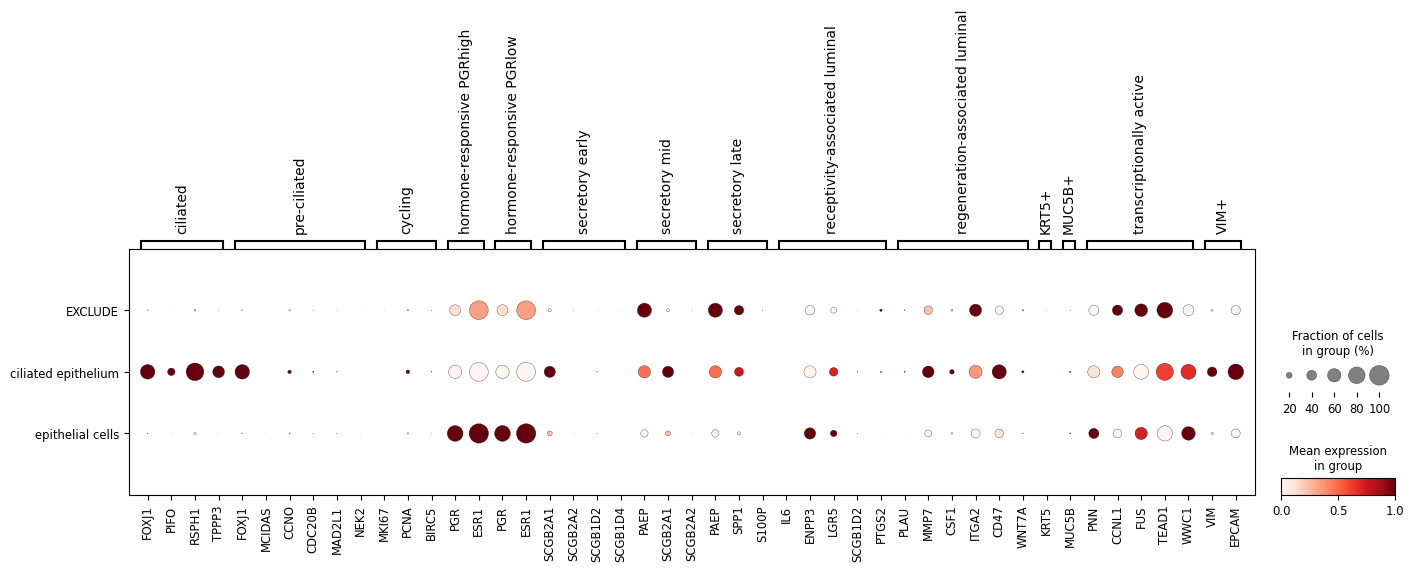

In [7]:
sc.pl.dotplot(a, MARKERS_present, groupby="committed_label", standard_scale="var", use_raw=USE_RAW,
              figsize=(ng * 0.22 + 6, a.obs["committed_label"].nunique() * 0.4 + 2))

## Module scores — the quantitative smear test

Score each Fig 2 signature per cell, average per leiden cluster, z-score each signature across
clusters so they're comparable. The heatmap + `best` table tell you which leiden cluster most
resembles which Fig 2 state, and what committed label it currently sits under.

In [8]:
score_cols = []
for state, genes in MARKERS_present.items():
    col = f"sig::{state}"
    sc.tl.score_genes(a, gene_list=genes, score_name=col, use_raw=USE_RAW)
    score_cols.append(col)

M = a.obs.groupby(GROUP)[score_cols].mean()
M.columns = [c.replace("sig::", "") for c in M.columns]
Mz = (M - M.mean(0)) / (M.std(0) + 1e-9)

best = pd.DataFrame({
    "committed_label": a.obs.groupby(GROUP)["committed_label"].agg(lambda s: s.value_counts().index[0]),
    "n_cells":         a.obs.groupby(GROUP).size(),
    "best_fig2_state": Mz.idxmax(1),
    "z":               Mz.max(1).round(2),
}).sort_values("z", ascending=False)
best

,committed_label,n_cells,best_fig2_state,z
leiden_scVI_3.0,,,,
43,ciliated epithelium,91,ciliated,6.98
23,epithelial cells,366,MUC5B+,5.46
11,EXCLUDE,238,KRT5+,4.90
22,EXCLUDE,548,KRT5+,4.65
29,epithelial cells,426,secretory early,4.51
44,EXCLUDE,231,secretory late,3.76
50,epithelial cells,325,receptivity-associated luminal,2.98
27,epithelial cells,90,cycling,2.82
48,epithelial cells,21,receptivity-associated luminal,2.62


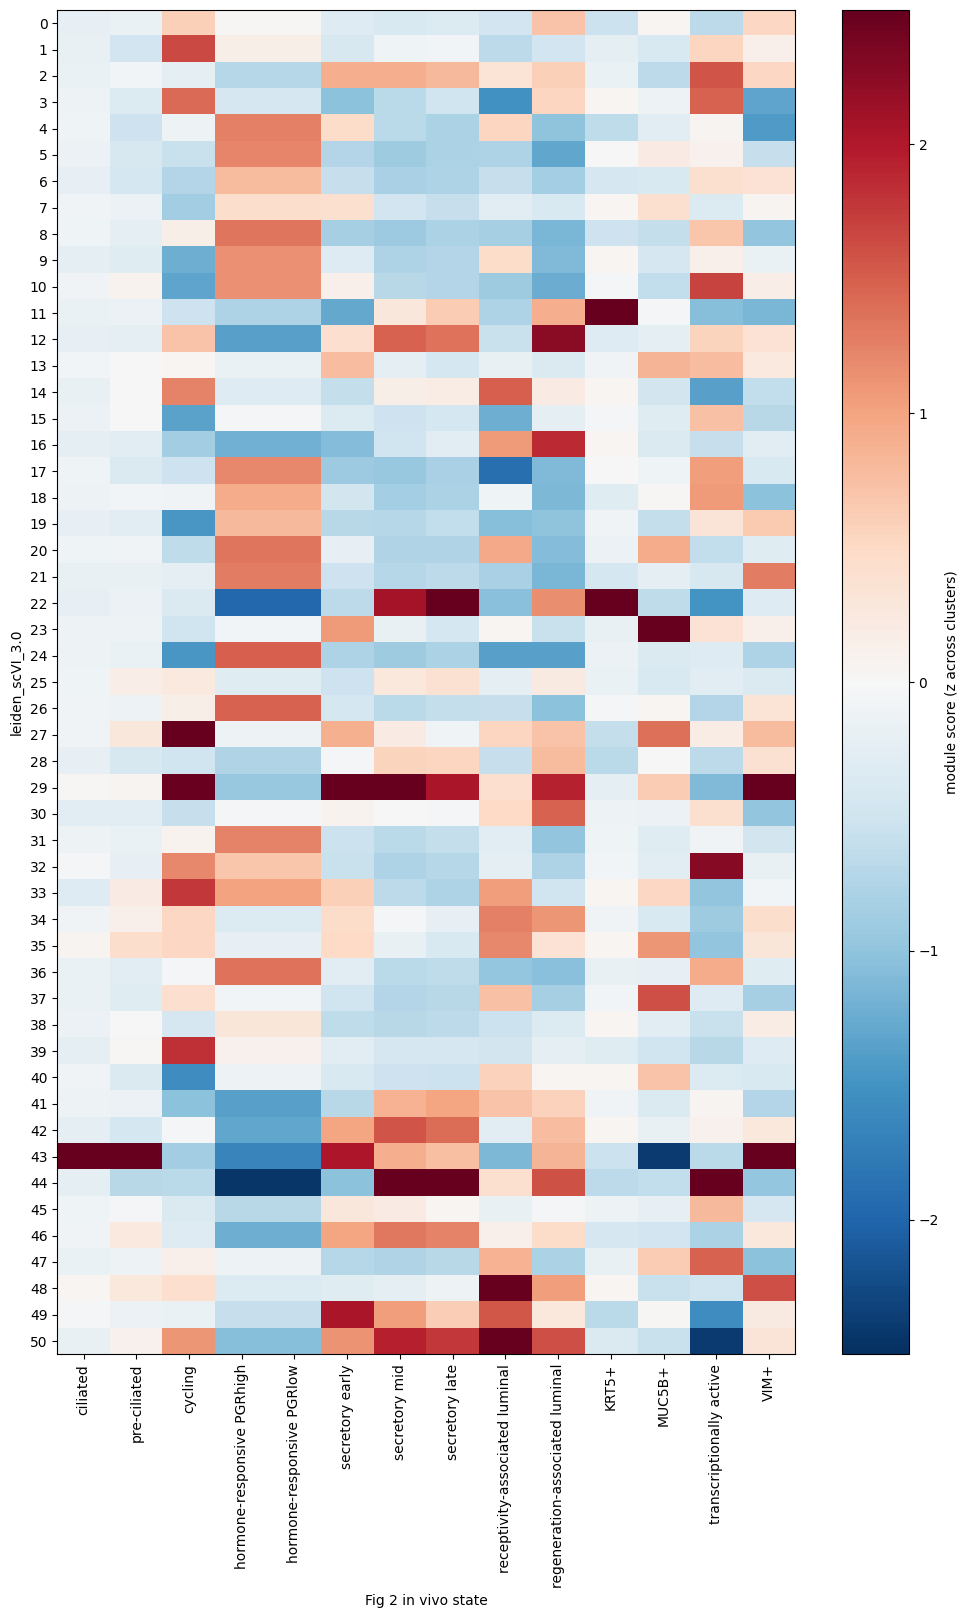

In [9]:
fig, ax = plt.subplots(figsize=(len(Mz.columns) * 0.5 + 3, len(Mz.index) * 0.28 + 2))
im = ax.imshow(Mz.values, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
ax.set_xticks(range(len(Mz.columns))); ax.set_xticklabels(Mz.columns, rotation=90)
ax.set_yticks(range(len(Mz.index)));   ax.set_yticklabels(Mz.index)
ax.set_xlabel("Fig 2 in vivo state"); ax.set_ylabel(GROUP)
fig.colorbar(im, ax=ax, label="module score (z across clusters)")
plt.tight_layout(); plt.show()

## How to read this

- Unlike the Fig 4 organoid panel, these are identity/phase states that **should** exist in cycling tissue. So a leiden cluster that scores strongly (red) for one Fig 2 state while currently sitting under a broad committed label is a real candidate for re-annotation — and several such hits means the re-write is worth doing.
- **Cycle-phase dependency:** which states appear depends on what you sampled. Regeneration-associated luminal is menstrual-specific (~50% menstrual, drops sharply in secretory); secretory early/mid/late need secretory samples; hormone-responsive PGRhigh is proliferative. A missing state may reflect sampling, not clustering.
- **Two relative states won't separate cleanly:** *hormone-responsive PGRlow* has no unique positive marker (it's PGR-low vs PGRhigh), and *secretory early→mid→late* is a gradient (secretoglobin-high → PAEP-high), so expect those to blur rather than form crisp blocks.
- Markers are curated from the paper's text, not the exact Fig 2C panel. Want me to pull the precise Fig 2C marker list from the repo (github.com/fmicompbio/IVMC-protocol) or the figure for pixel-fidelity?